In [1]:
# Self-contained setup: loads the rating data, splits by release date at 2017-11-18, builds 3 expanding validation folds inside the training period, and defines the preprocessing pipeline, six feature presets, and a linear regression validation baseline that the KNN search cell relies on.
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

DATA_FILE = "../../data/model_data_rating.csv"
CUTOFF_DATE = "2017-11-18"
N_VALIDATION_SPLITS = 3
TARGET = "vote_average"
CATEGORICAL_FEATURES = ["us_certification", "release_month"]

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
y = movies[TARGET].copy()

basics = ["runtime", "log_budget", "us_certification", "release_month", "is_sequel", "is_english"]
original = ["runtime", "log_budget", "dir_prior_films_log1p", "dir_prior_rating_smoothed",
            "dir_prior_rated_films_log1p", "us_certification", "release_month",
            "is_sequel", "is_english", "dir_no_rating_history"]
feature_versions = {
    "Movie basics": basics,
    "+ Director experience": basics + ["dir_prior_films_log1p"],
    "Original director history": original,
    "Actor/company/franchise": basics + [
        "lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable",
        "company_films_5yr_log1p", "franchise_prior_films_log1p"],
    "Basics + four genres": basics + ["genre_drama", "genre_comedy", "genre_action", "genre_horror"],
    "Compact mix": basics + [
        "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
        "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p"],
}

comparison_features = list(dict.fromkeys(c for cols in feature_versions.values() for c in cols))
comparison_X = movies[comparison_features].copy()
for column in CATEGORICAL_FEATURES:
    comparison_X[column] = comparison_X[column].map(lambda v: str(v) if pd.notna(v) else np.nan)
comparison_binary = ["is_sequel", "is_english", "dir_no_rating_history", "backfill_unavailable"] + [
    c for c in movies if c.startswith("genre_")]

def make_feature_model(columns):
    numeric = [c for c in columns if c not in CATEGORICAL_FEATURES + comparison_binary]
    categorical = [c for c in CATEGORICAL_FEATURES if c in columns]
    binary = [c for c in columns if c in comparison_binary]
    return Pipeline([
        ("preprocessor", ColumnTransformer([
            ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                  ("scaler", StandardScaler())]), numeric),
            ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                      ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), categorical),
            ("binary", "passthrough", binary),
        ])),
        ("model", LinearRegression()),
    ])

train = movies["release_date"].lt(pd.Timestamp(CUTOFF_DATE))
test = ~train
y_train, y_test = y.loc[train], y.loc[test]

training_dates = movies.loc[train, "release_date"]
unique_dates = np.sort(training_dates.unique())
feature_splits = []
for earlier, later in TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates):
    fit_rows = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_rows = training_dates.index[training_dates.isin(unique_dates[later])]
    feature_splits.append((fit_rows, validation_rows))

linear_maes = {}
for version, columns in feature_versions.items():
    fold_maes = []
    for fit_rows, validation_rows in feature_splits:
        model = make_feature_model(columns)
        model.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
        fold_maes.append(mean_absolute_error(y.loc[validation_rows], model.predict(comparison_X.loc[validation_rows])))
    linear_maes[version] = np.mean(fold_maes)
feature_comparison = pd.DataFrame({"MAE": linear_maes})

print(f"{len(movies):,} movies | train {train.sum():,} | test {test.sum():,} | folds {len(feature_splits)}")
display(feature_comparison.round(4))

13,276 movies | train 9,405 | test 3,871 | folds 3


,MAE
Movie basics,0.5702
+ Director experience,0.5704
Original director history,0.5638
Actor/company/franchise,0.5698
Basics + four genres,0.5425
Compact mix,0.5604


In [3]:
# Searches KNN settings (k, weighting, distance metric) across the six feature presets, ranks every combination by mean validation MAE over the 3 chronological folds, and compares the best one to the linear regression's validation MAE.
from itertools import product
from sklearn.neighbors import KNeighborsRegressor

KNN_GRID = {
    "n_neighbors": [5, 10, 15, 20, 30, 40, 50, 75, 100],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

def make_knn_model(columns, **params):
    pipeline = make_feature_model(columns)
    pipeline.set_params(model=KNeighborsRegressor(**params))
    return pipeline

knn_rows = []
for version, columns in feature_versions.items():
    for k, w, p in product(KNN_GRID["n_neighbors"], KNN_GRID["weights"], KNN_GRID["p"]):
        fold_maes = []
        for fit_rows, validation_rows in feature_splits:
            knn = make_knn_model(columns, n_neighbors=k, weights=w, p=p)
            knn.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
            predicted = knn.predict(comparison_X.loc[validation_rows])
            fold_maes.append(mean_absolute_error(y.loc[validation_rows], predicted))
        knn_rows.append({"Version": version, "n_neighbors": k, "weights": w, "p": p,
                         "Val_MAE": np.mean(fold_maes), "Val_MAE_std": np.std(fold_maes, ddof=1)})

knn_search = pd.DataFrame(knn_rows).sort_values("Val_MAE").reset_index(drop=True)
display(knn_search.head(10).round(4))
best_knn = knn_search.iloc[0]
print("Best KNN:", best_knn.to_dict())
print("Linear regression best validation MAE:", round(feature_comparison["MAE"].min(), 4))

,Version,n_neighbors,weights,p,Val_MAE,Val_MAE_std
0,Basics + four genres,40,uniform,2,0.5370,0.0139
1,Basics + four genres,50,uniform,2,0.5371,0.0133
2,Basics + four genres,30,uniform,2,0.5378,0.0146
3,Basics + four genres,50,uniform,1,0.5388,0.0132
4,Basics + four genres,75,uniform,2,0.5389,0.0153
5,Basics + four genres,40,uniform,1,0.5390,0.0142
6,Basics + four genres,30,uniform,1,0.5392,0.0149
7,Basics + four genres,20,uniform,2,0.5404,0.0141
8,Basics + four genres,75,uniform,1,0.5407,0.0145
9,Basics + four genres,20,uniform,1,0.5409,0.0155


Best KNN: {'Version': 'Basics + four genres', 'n_neighbors': 40, 'weights': 'uniform', 'p': 2, 'Val_MAE': 0.5370301270647445, 'Val_MAE_std': 0.013865301737755992}
Linear regression best validation MAE: 0.5425


In [5]:
# Refits the validation-selected KNN and the validation-selected linear regression on all training movies, then scores both (plus a training-mean baseline) once on the held-out test movies.
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

def score(name, split, actual, predicted):
    return {"Model": name, "Split": split,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

knn_version = best_knn["Version"]
knn_k = int(best_knn["n_neighbors"])
knn_columns = feature_versions[knn_version]
final_knn = make_knn_model(knn_columns, n_neighbors=knn_k,
                           weights=best_knn["weights"], p=int(best_knn["p"]))
final_knn.fit(comparison_X.loc[train], y_train)
knn_test_prediction = final_knn.predict(comparison_X.loc[test])

linear_version = feature_comparison["MAE"].idxmin()
final_linear = make_feature_model(feature_versions[linear_version])
final_linear.fit(comparison_X.loc[train], y_train)
linear_test_prediction = final_linear.predict(comparison_X.loc[test])

baseline = DummyRegressor(strategy="mean").fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))

knn_name = "KNN (" + knn_version + ", k=" + str(knn_k) + ")"
linear_name = "Linear regression (" + linear_version + ")"

test_results = pd.DataFrame([
    score("Training mean baseline", "Test", y_test, baseline_prediction),
    score(linear_name, "Test", y_test, linear_test_prediction),
    score(knn_name, "Test", y_test, knn_test_prediction),
])
display(test_results.round(4))

,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Linear regression (Basics + four genres),Test,0.5625,0.7152,0.0849
2,"KNN (Basics + four genres, k=40)",Test,0.5615,0.7189,0.0755


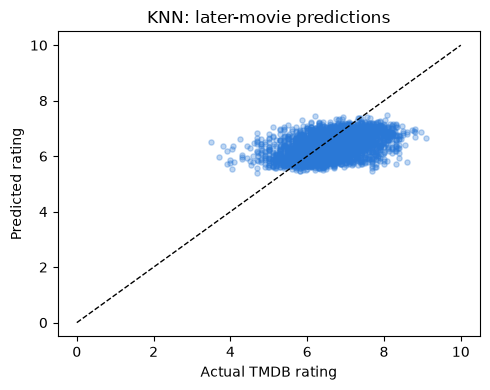

In [8]:
# Scatter plot of actual vs. predicted TMDB ratings for the final KNN on the test movies; the dashed diagonal marks perfect predictions.
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 4))
plt.scatter(y_test, knn_test_prediction, alpha=0.3, s=14, color="#2a78d6")
plt.plot([0, 10], [0, 10], "k--", linewidth=1)
plt.xlabel("Actual TMDB rating")
plt.ylabel("Predicted rating")
plt.title("KNN: later-movie predictions")
plt.tight_layout()
plt.show()

**KNN model for predicting TMDB viewer rating**

We tested a K-Nearest Neighbors regressor to predict a movie's TMDB `vote_average`. Features were standardized and one-hot encoded using only training data. We tuned the number of neighbors (k), weighting scheme, distance metric, and feature set to minimize mean absolute error (MAE) across three expanding chronological validation folds inside the training period (movies before 2017-11-18). The best configuration used the "Basics + four genres" feature set with k=40, uniform weights, and Euclidean distance, giving a validation MAE of 0.537 versus 0.543 for the best linear regression.

On the held-out test period (movies from 2017-11-18 onward), KNN scored an MAE of 0.5615 and linear regression scored 0.5625. Both improved on the training-mean baseline (0.6123) by about 0.05 rating points, but the difference between the two models is far smaller than the fold-to-fold validation variation (about 0.014), so we can't say KNN is better.

The actual vs. predicted plot shows why. Predictions cluster between roughly 5.5 and 7.5, while actual ratings range from about 3.5 to 9, so the model regresses toward the average and misses highly and poorly rated movies. This matches the low test R² (0.076). The current features capture only a small part of what drives viewer ratings, and further tuning of KNN is unlikely to help. Gains would more likely come from stronger predictors.